# Customer Churn Prediction Using Machine Learning
# 1. Business Understanding
# 1.1 Background

# Customer churn occurs when a customer stops using a company's products or services. For businesses that depend on recurring customers, reducing churn is important for maintaining revenue and long-term growth.

# Customers may leave a company for different reasons, including pricing, service quality, contract conditions, customer support, or alternative providers. Analysing customer data can help businesses identify patterns associated with customer churn.

# Machine learning can be used to analyse historical customer information and predict which existing customers are more likely to leave. Such predictions can help businesses identify high-risk customers and take proactive measures to improve customer retention.

# 1.2 Problem Statement

# Telecommunications companies serve customers with different demographic characteristics, service subscriptions, contracts, and billing patterns. However, identifying customers who are likely to leave before they actually churn can be challenging.

# If a company only reacts after customers have cancelled their services, opportunities to retain those customers may be lost. Therefore, a predictive approach is needed to identify customers who are at greater risk of churn.

# This project aims to develop a machine-learning classification model that predicts whether a customer is likely to churn based on their demographic, account, service, contract, and billing information.

# 1.3 Aim

# The aim of this project is to develop and evaluate a machine-learning model capable of predicting customer churn and identifying customers who are at increased risk of leaving a telecommunications service provider.

# 1.4 Objectives

# The objectives of this project are to:

# Understand and analyse the customer churn dataset.
# Assess the quality and structure of the data.
# Explore patterns and relationships associated with customer churn.
# Clean and preprocess the data appropriately.
# Engineer useful features where appropriate.
# Develop multiple machine-learning classification models.
# Compare model performance using appropriate evaluation metrics.
# Use stratified cross-validation to obtain reliable performance estimates.
# Tune the hyperparameters of promising models.
# Select an appropriate final model based on predictive and business considerations.
# Evaluate the final model on previously unseen test data.
# Identify important factors influencing churn predictions.
# Analyse probability thresholds for identifying customers at risk.
# Provide recommendations that could support customer-retention strategies.
# 1.4 Research Questions
# What characteristics are associated with customer churn?
# Which customer and service characteristics are most strongly associated with churn?
# Which machine-learning algorithm performs best for predicting customer churn?
# How effectively can the selected model identify customers who are likely to churn?
# Which features contribute most to churn predictions?
# How can churn predictions support customer-retention decisions?
# 1.5 Business Value

# A reliable churn prediction system can help a telecommunications company identify customers who are at increased risk of leaving. The company could then target these customers with appropriate retention strategies, potentially reducing customer losses and improving customer lifetime value.

# 1.6 Machine-Learning Problem

# Customer churn prediction is a supervised binary classification problem.

# The target variable is Churn:

# No — the customer remains with the company.
# Yes — the customer leaves the company.

# The machine-learning models will learn patterns from historical customer information and use those patterns to predict the likelihood of churn for previously unseen customers.

# 1.7 Project Methodology

# The project will follow an end-to-end machine-learning workflow:

# Business Understanding → Data Understanding → Data Quality Assessment → Exploratory Data Analysis → Feature Engineering → Data Preprocessing → Train-Test Split → Baseline Modelling → Cross-Validation → Model Comparison → Hyperparameter Tuning → Threshold Analysis → Final Evaluation → Model Interpretation → Business Recommendations → Conclusion

# 2. Import Libraries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

# load data set

In [3]:
df = pd.read_csv("Customer-Churn.csv"); df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

# 3.2 Data Quality Assessment

In [10]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df['customerID'].duplicated().sum()

np.int64(0)

In [16]:
df.Churn.value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [20]:
df.Churn.value_counts(normalize=True)*100


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [18]:
df['TotalCharges'].dtype

<StringDtype(storage='python', na_value=nan)>

In [19]:
df['TotalCharges'].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str

# 3.3 Target Variable Distribution

In [21]:
churn_percentage = df['Churn'].value_counts(normalize=True) * 100
churn_percentage

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [ ]:
sns.countplot(data = df, x = "Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.show()

#  3.4 Data Quality Findings

# The initial data-quality assessment produced several important findings.

# The dataset contains 7,043 customer records and 21 variables. No duplicated rows were identified, indicating that there are no exact duplicate observations in the dataset.

# The `Churn` variable contains two classes. A total of 5,174 customers did not churn, while 1,869 customers churned. This corresponds to approximately 73.5% non-churned customers and 26.5% churned customers. Therefore, the target variable exhibits a moderate degree of class imbalance.

# The `TotalCharges` variable requires further investigation. Although it represents a numerical monetary quantity, it is currently stored using a string data type. This means that it cannot be directly treated as a numerical feature by machine-learning algorithms until its data type and contents have been properly assessed.

# No missing values were detected using the standard `isna()` check. However, because `TotalCharges` is stored as a string, potential blank-string values must be investigated separately before concluding that the variable contains no missing information.

# The dataset will therefore undergo further data-quality checks before preprocessing and modelling.


# 3.5 Investigate TotalCharges

In [25]:
df[df['TotalCharges'].str.strip() == ' '].sum()

customerID             
gender                 
SeniorCitizen         0
Partner                
Dependents             
tenure                0
PhoneService           
MultipleLines          
InternetService        
OnlineSecurity         
OnlineBackup           
DeviceProtection       
TechSupport            
StreamingTV            
StreamingMovies        
Contract               
PaperlessBilling       
PaymentMethod          
MonthlyCharges      0.0
TotalCharges           
Churn                  
dtype: object

In [26]:
df[df['TotalCharges'].str.strip() == ' '].shape

(0, 21)

In [27]:
df['TotalCharges'].str.strip().eq('').sum()

np.int64(11)

In [28]:
df[df['TotalCharges'].str.strip() == ' '][
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn


In [29]:
df.loc[df['TotalCharges'].str.strip().eq(''), 'tenure'].value_counts()

tenure
0    11
Name: count, dtype: int64

In [30]:
df.loc[df['TotalCharges'].str.strip().eq(''), 'MonthlyCharges'].describe()

count    11.000000
mean     41.418182
std      23.831484
min      19.700000
25%      20.125000
50%      25.750000
75%      58.975000
max      80.850000
Name: MonthlyCharges, dtype: float64

In [31]:
df['TotalCharges'] = df['TotalCharges'].str.strip()
df['TotalCharges'] = df['TotalCharges'].replace('', np.nan)

In [32]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [33]:
df['TotalCharges'].dtype

dtype('float64')

In [34]:
df['TotalCharges'].isna().sum()

np.int64(11)

In [35]:
df[['tenure', 'MonthlyCharges', 'TotalCharges']].head()

,tenure,MonthlyCharges,TotalCharges
0,1,29.85,29.85
1,34,56.95,1889.50
2,2,53.85,108.15
3,45,42.30,1840.75
4,2,70.70,151.65


In [41]:
print("Negative tenure:", (df['tenure'] < 0).sum())
print("Negative monthly charges:", (df['MonthlyCharges'] < 0).sum())
print("Negative total charges:", (df['TotalCharges'] < 0).sum())

Negative tenure: 0
Negative monthly charges: 0
Negative total charges: 0


## 3.6 Final Data Quality Checks

In [37]:
df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [38]:
df['SeniorCitizen'].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

In [39]:
categorical_cols = df.select_dtypes(include='str').columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429


In [40]:
df['customerID'].nunique()

7043

# # 4. Exploratory Data Analysis

# ## 4.1 Churn Distribution

# The first stage of exploratory data analysis examines the distribution of the target variable, `Churn`. Understanding the proportion of customers who churned and those who remained is important because it determines the baseline level of churn and helps assess whether class imbalance may affect model development and evaluation.

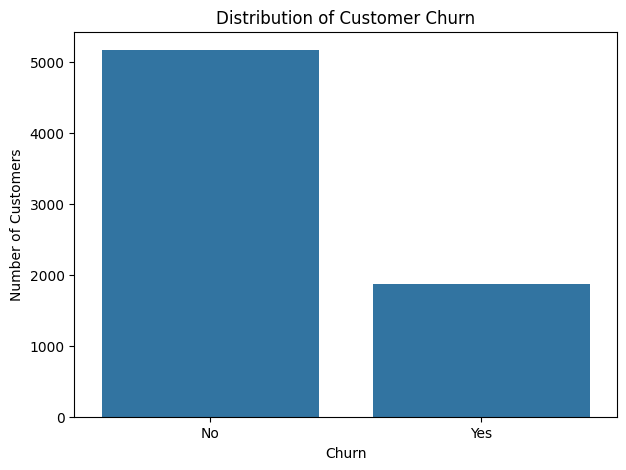

In [42]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title('Distribution of Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()



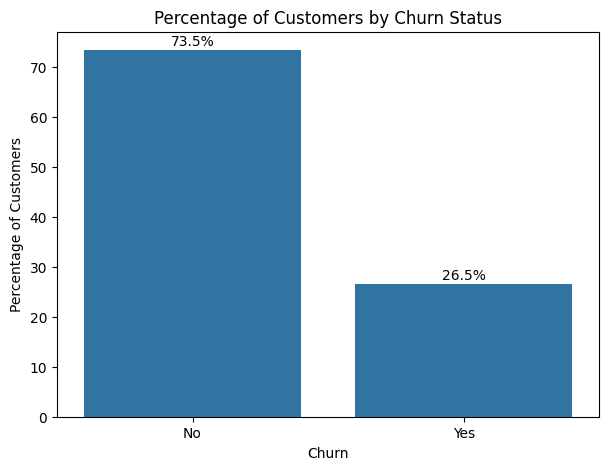

In [43]:
churn_pct = df['Churn'].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=churn_pct.index,
    y=churn_pct.values
)

plt.title('Percentage of Customers by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Percentage of Customers')

for i, value in enumerate(churn_pct.values):
    ax.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.show()

# ### Interpretation

# The dataset contains 7,043 customers, of whom 5,174 did not churn and 1,869 churned. Therefore, approximately 73.5% of customers remained with the company, while approximately 26.5% churned.

# This indicates a moderate class imbalance, with non-churned customers representing the majority class. Consequently, accuracy alone will not be sufficient for evaluating the machine-learning models. Metrics such as precision, recall, F1-score, ROC-AUC, and particularly Precision-Recall AUC will also be considered during model evaluation.

# From a business perspective, the approximately 26.5% churn rate indicates that a substantial proportion of the customer base is leaving the company. Identifying customers who are at increased risk of churn could therefore provide meaningful opportunities for targeted retention strategies.

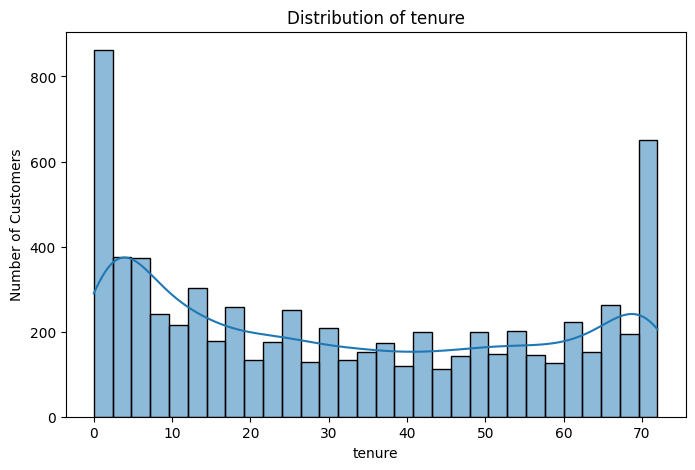

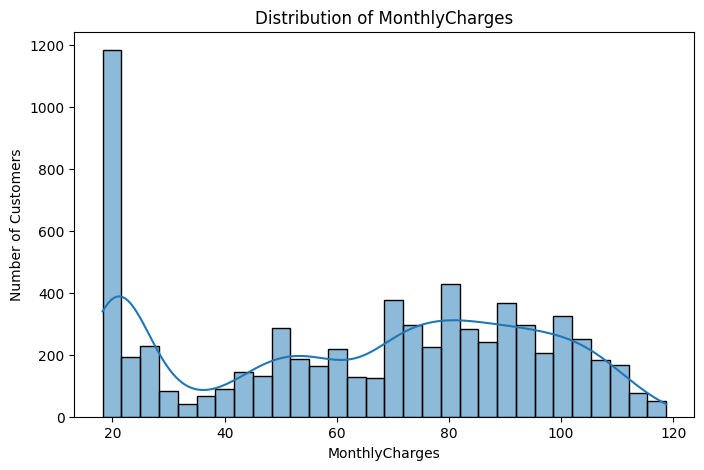

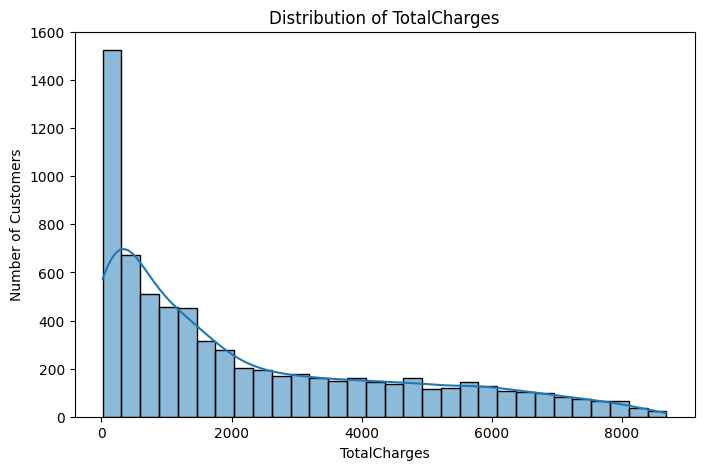

In [44]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in numerical_cols:
    plt.figure(figsize=(8, 5))
    
    sns.histplot(data=df, x=col, bins=30, kde=True)
    
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Number of Customers')
    
    plt.show()

# ##  Numerical Variables vs Churn

# To investigate factors associated with customer churn, the numerical variables are compared across churn groups. Boxplots are used to examine differences in the distributions of tenure, monthly charges, and total charges between customers who churned and those who remained.

# These comparisons provide an initial understanding of whether customer tenure and spending behaviour may be associated with churn.

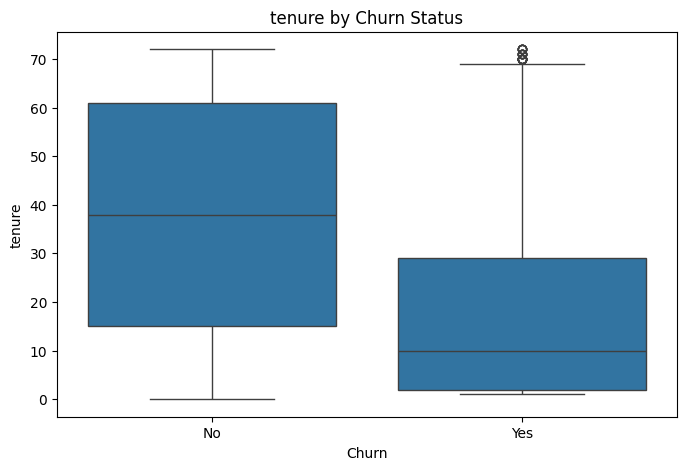

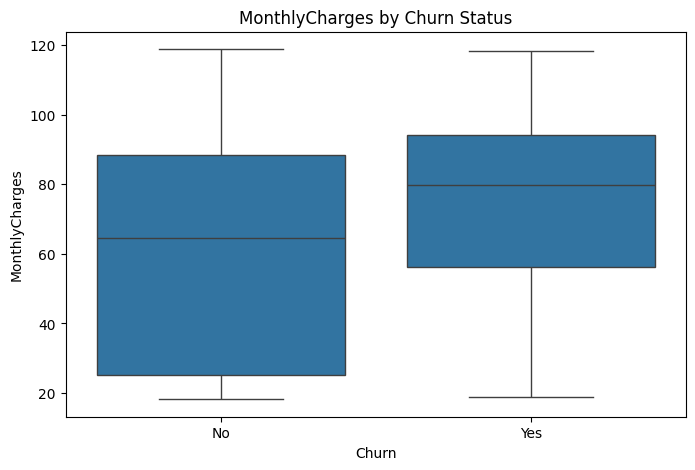

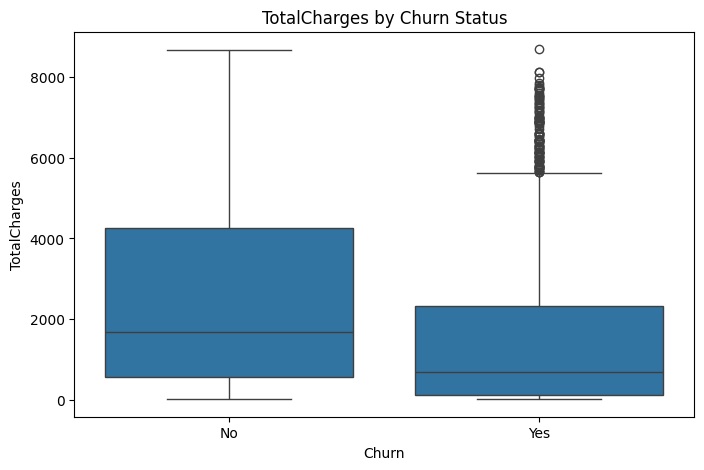

In [45]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in numerical_cols:
    plt.figure(figsize=(8, 5))
    
    sns.boxplot(data=df, x='Churn', y=col)
    
    plt.title(f'{col} by Churn Status')
    plt.xlabel('Churn')
    plt.ylabel(col)
    
    plt.show()

# ##  Numerical Summary by Churn

# Descriptive statistics are calculated separately for churned and non-churned customers to quantify differences observed in the visual analysis.

In [47]:
df.groupby('Churn')[numerical_cols].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).T

Churn                           No          Yes
tenure         count   5174.000000  1869.000000
               mean      37.569965    17.979133
               median    38.000000    10.000000
               std       24.113777    19.531123
               min        0.000000     1.000000
               max       72.000000    72.000000
MonthlyCharges count   5174.000000  1869.000000
               mean      61.265124    74.441332
               median    64.425000    79.650000
               std       31.092648    24.666053
               min       18.250000    18.850000
               max      118.750000   118.350000
TotalCharges   count   5163.000000  1869.000000
               mean    2555.344141  1531.796094
               median  1683.600000   703.550000
               std     2329.456984  1890.822994
               min       18.800000    18.850000
               max     8672.450000  8684.800000

# ##  Churn Rate by Tenure

# Customer tenure may be an important indicator of churn risk. Customers who have recently joined a company may behave differently from long-term customers.

# To investigate this relationship, tenure will be grouped into meaningful intervals and the churn rate within each group will be calculated.

In [49]:
bins = [0, 12, 24, 36, 48, 60, 72]
labels = ['0-12', '13-24', '25-36', '37-48', '49-60', '61-72']

df['tenure_group'] = pd.cut(
    df['tenure'],
    bins=bins,
    labels=labels,
    include_lowest=True
)


tenure_churn = (
    df.groupby('tenure_group', observed=True)['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
)

tenure_churn

tenure_group
0-12     47.438243
13-24    28.710938
25-36    21.634615
37-48    19.028871
49-60    14.423077
61-72     6.609808
Name: Churn, dtype: float64

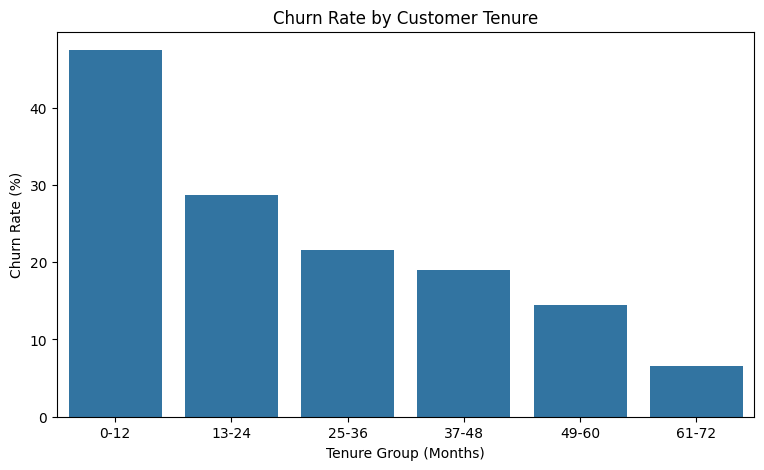

In [50]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values
)

plt.title('Churn Rate by Customer Tenure')
plt.xlabel('Tenure Group (Months)')
plt.ylabel('Churn Rate (%)')

plt.show()

# Churn Rate by Internet Service

# Internet service type may influence customer satisfaction, pricing, and service experience. This analysis examines whether churn rates differ across the available internet service categories.

In [51]:
internet_churn = (
    df.groupby('InternetService')['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .sort_values(ascending=False)
)

internet_churn

InternetService
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn, dtype: float64

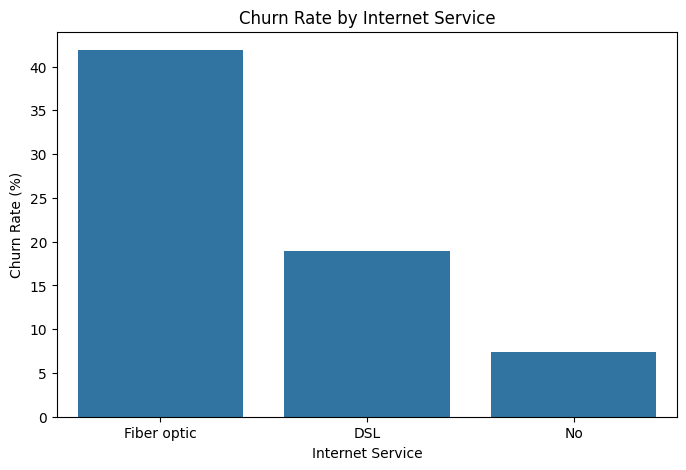

In [52]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)

plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')

plt.show()

In [53]:
pd.crosstab(df['InternetService'], df['Churn'])

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


# Churn Rate by Payment Method

# Payment method may be associated with customer behaviour and retention. The churn rate is therefore compared across payment methods to identify potential differences between customer groups.

In [54]:
payment_churn = (
    df.groupby('PaymentMethod')['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .sort_values(ascending=False)
)

payment_churn

PaymentMethod
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Churn, dtype: float64

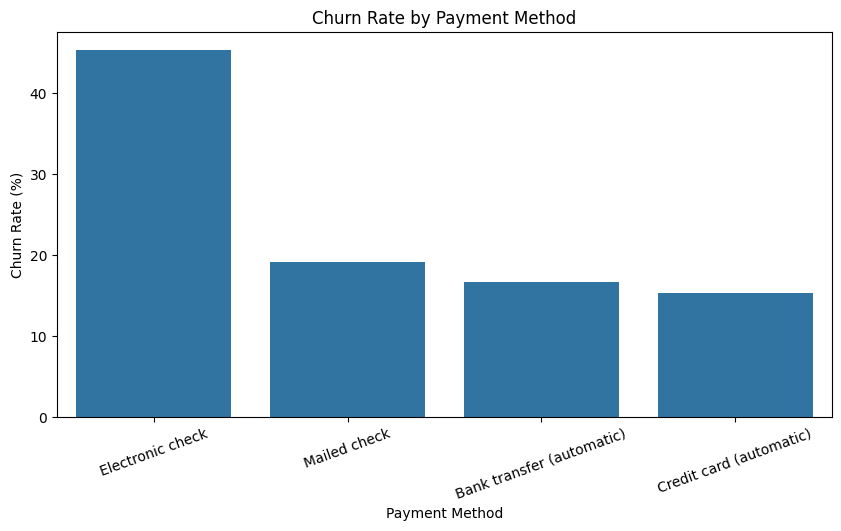

In [55]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values
)

plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=20)

plt.show()

In [56]:
pd.crosstab(df['PaymentMethod'], df['Churn'])

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [57]:
binary_cols = [
    'gender',
    'SeniorCitizen',
    'Partner',
    'Dependents',
    'PhoneService',
    'PaperlessBilling'
]

for col in [
    'gender',
    'Partner',
    'Dependents',
    'PhoneService',
    'PaperlessBilling'
]:
    
    churn_rate = (
        df.groupby(col)['Churn']
          .apply(lambda x: (x == 'Yes').mean() * 100)
          .sort_values(ascending=False)
    )
    
    print(f"\n{col}")
    print(churn_rate)


gender
gender
Female    26.920872
Male      26.160338
Name: Churn, dtype: float64

Partner
Partner
No     32.957979
Yes    19.664903
Name: Churn, dtype: float64

Dependents
Dependents
No     31.279140
Yes    15.450237
Name: Churn, dtype: float64

PhoneService
PhoneService
Yes    26.709637
No     24.926686
Name: Churn, dtype: float64

PaperlessBilling
PaperlessBilling
Yes    33.565092
No     16.330084
Name: Churn, dtype: float64


# ## Categorical Variables vs Churn

# Churn rates are examined across the categorical variables to identify customer segments that exhibit different levels of churn. This provides an initial understanding of which customer characteristics may be useful predictors for the machine-learning models.

In [58]:
def churn_rate_by_category(data, columns):
    results = {}
    
    for col in columns:
        results[col] = (
            data.groupby(col)['Churn']
            .apply(lambda x: (x == 'Yes').mean() * 100)
            .sort_values(ascending=False)
        )
    
    return results

In [59]:
categorical_cols = [
    'gender',
    'SeniorCitizen',
    'Partner',
    'Dependents',
    'PhoneService',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'Contract',
    'PaperlessBilling',
    'PaymentMethod'
]

churn_rates = churn_rate_by_category(df, categorical_cols)

for col, result in churn_rates.items():
    print(f"\n{'='*50}")
    print(col)
    print(result)


gender
gender
Female    26.920872
Male      26.160338
Name: Churn, dtype: float64

SeniorCitizen
SeniorCitizen
1    41.681261
0    23.606168
Name: Churn, dtype: float64

Partner
Partner
No     32.957979
Yes    19.664903
Name: Churn, dtype: float64

Dependents
Dependents
No     31.279140
Yes    15.450237
Name: Churn, dtype: float64

PhoneService
PhoneService
Yes    26.709637
No     24.926686
Name: Churn, dtype: float64

MultipleLines
MultipleLines
Yes                 28.609896
No                  25.044248
No phone service    24.926686
Name: Churn, dtype: float64

InternetService
InternetService
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn, dtype: float64

OnlineSecurity
OnlineSecurity
No                     41.766724
Yes                    14.611194
No internet service     7.404980
Name: Churn, dtype: float64

OnlineBackup
OnlineBackup
No                     39.928756
Yes                    21.531494
No internet service     7.404980
Name: Chur

In [60]:
def plot_churn_rate(data, columns):
    
    for col in columns:
        
        churn_rate = (
            data.groupby(col)['Churn']
            .apply(lambda x: (x == 'Yes').mean() * 100)
            .sort_values(ascending=False)
        )
        
        plt.figure(figsize=(8, 5))
        
        sns.barplot(
            x=churn_rate.index,
            y=churn_rate.values
        )
        
        plt.title(f'Churn Rate by {col}')
        plt.xlabel(col)
        plt.ylabel('Churn Rate (%)')
        
        plt.xticks(rotation=20)
        plt.show()

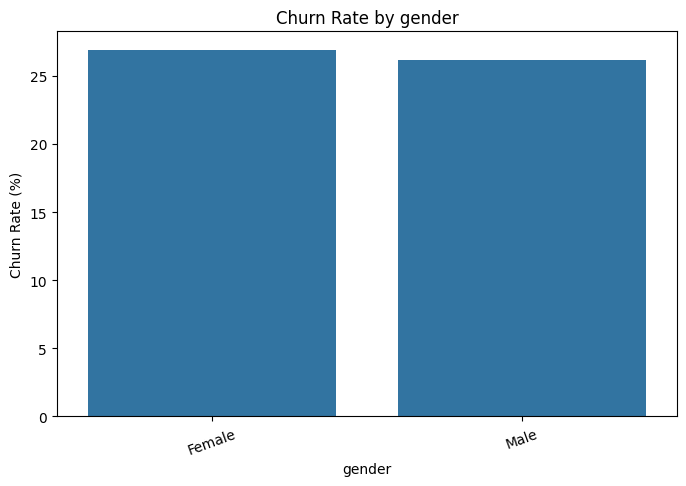

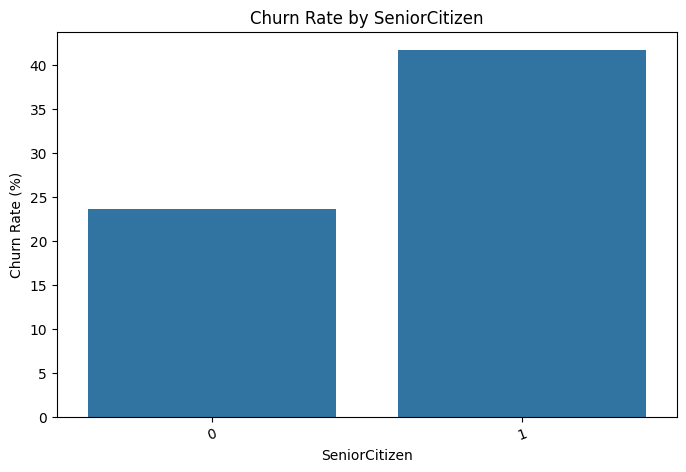

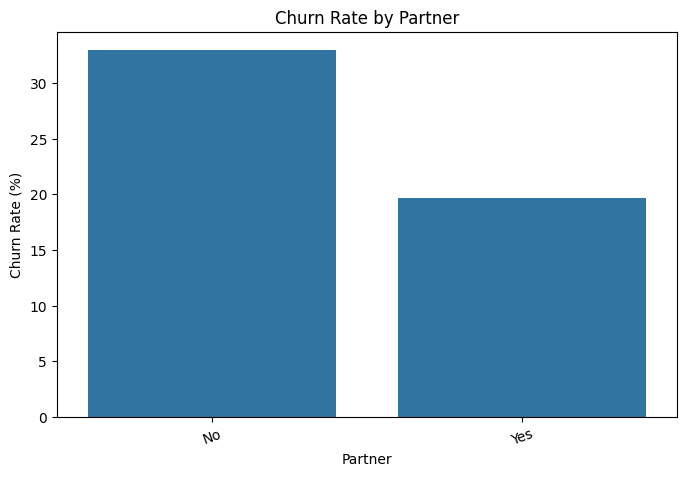

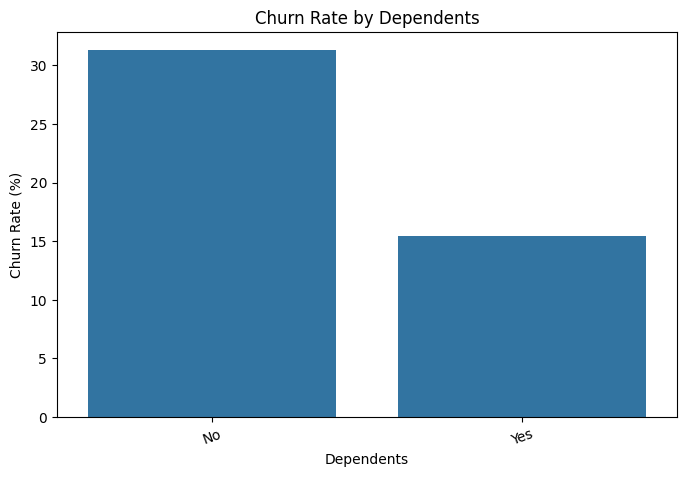

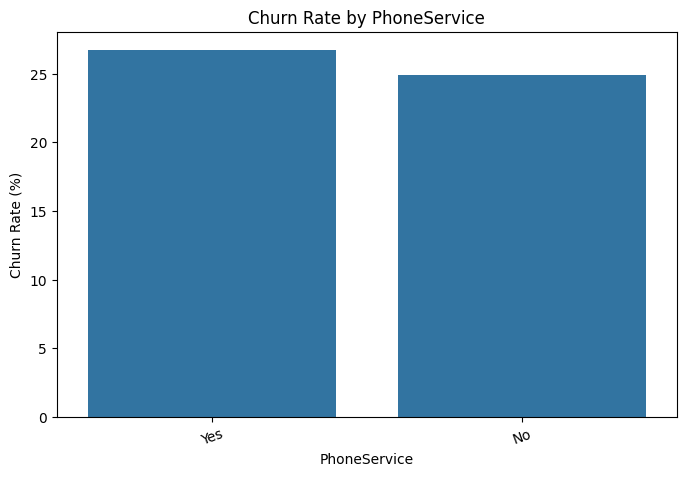

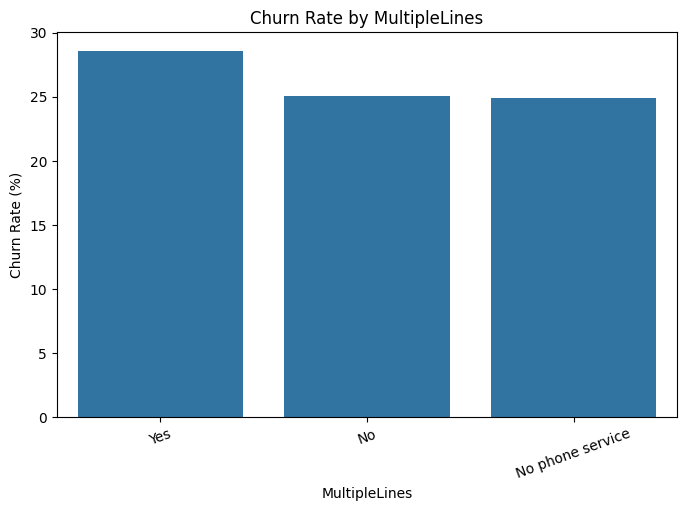

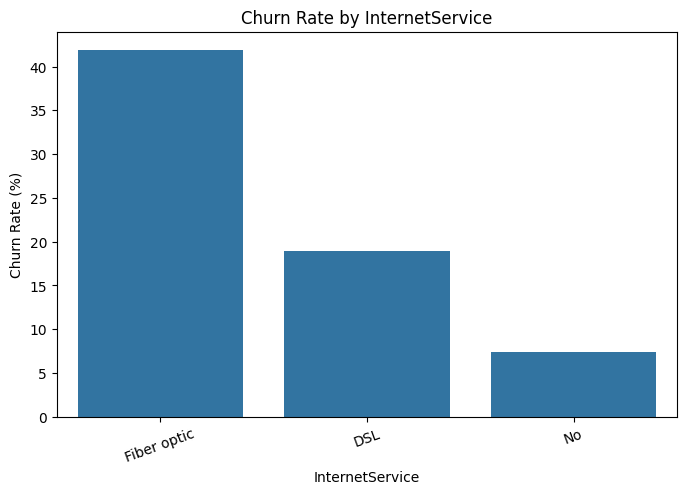

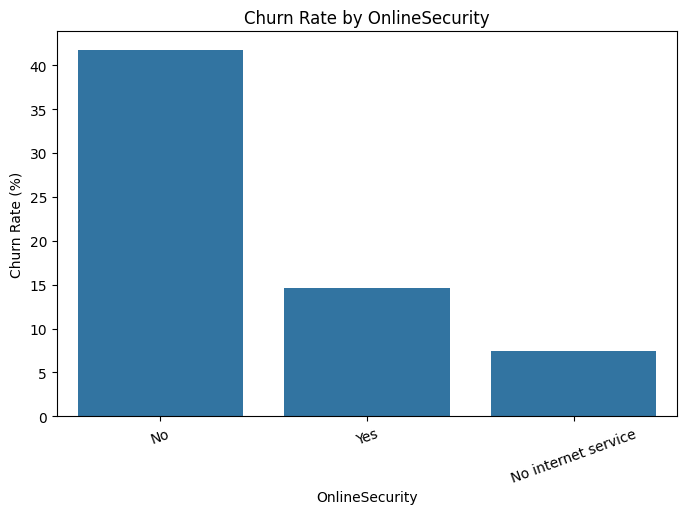

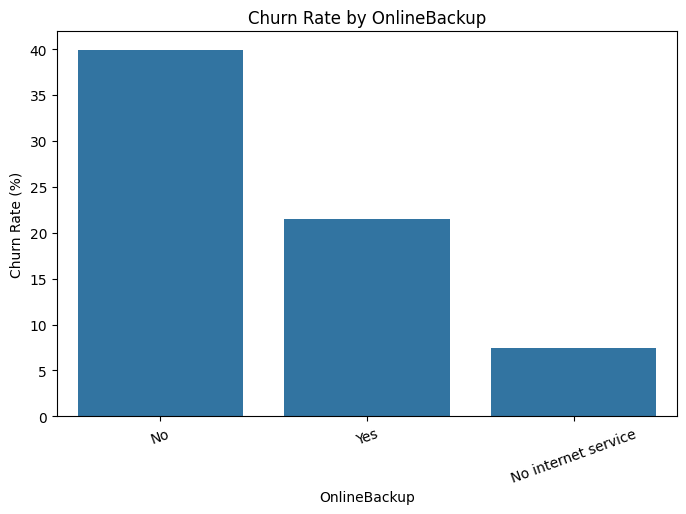

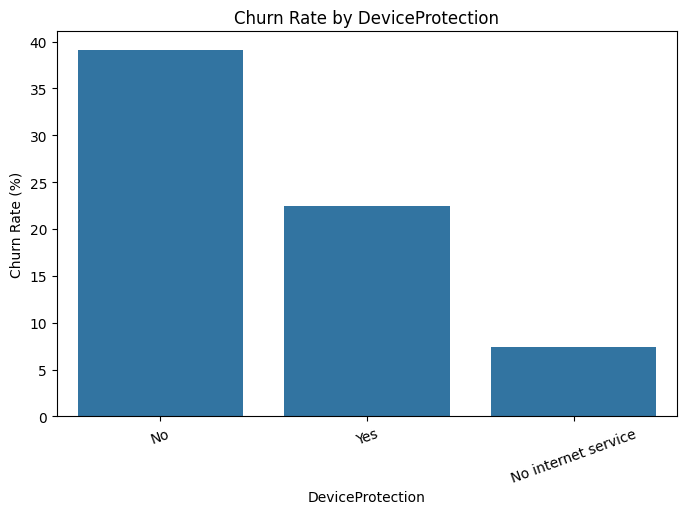

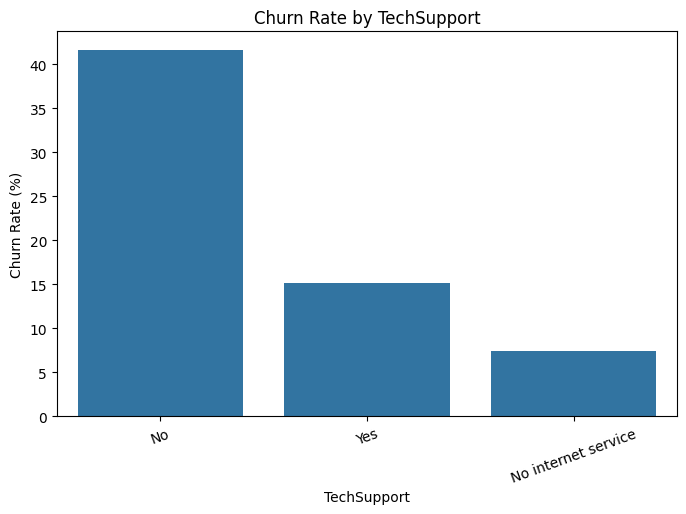

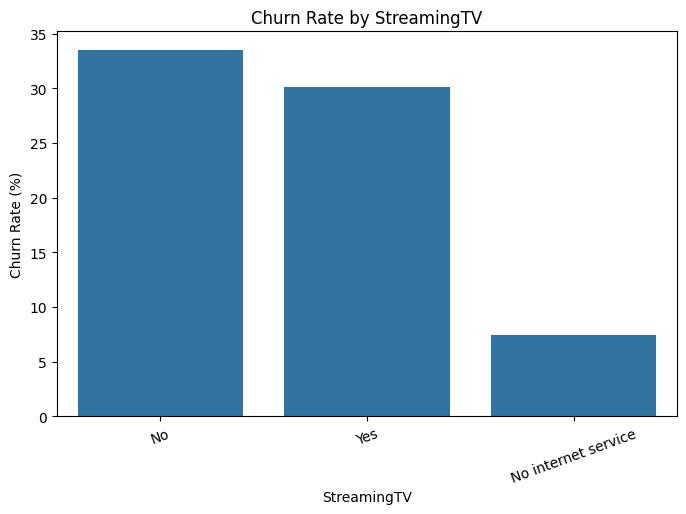

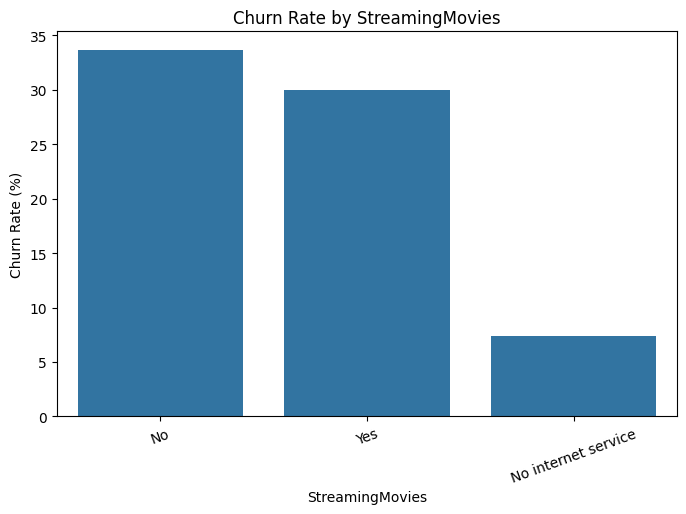

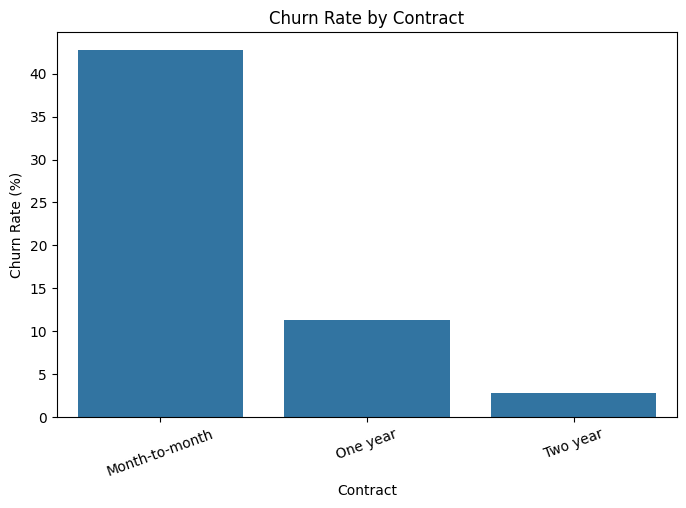

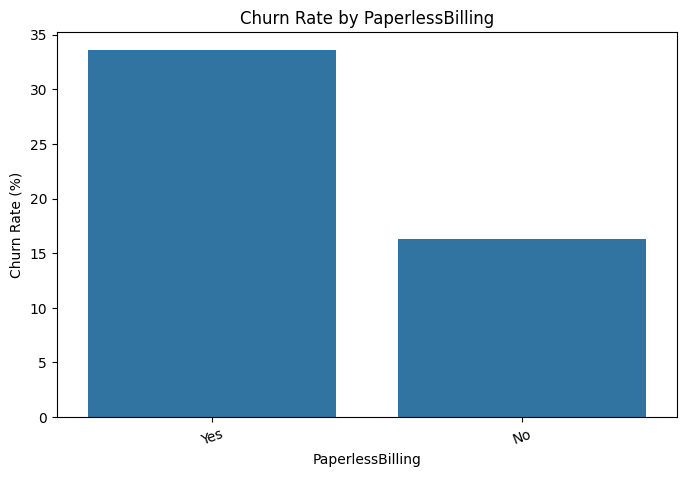

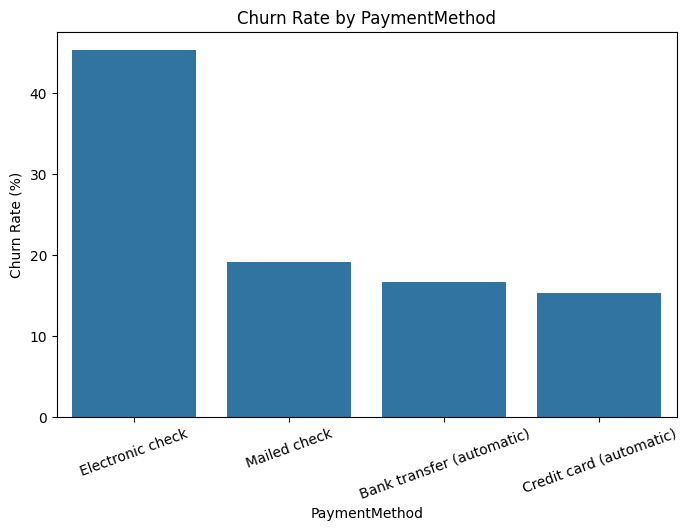

In [61]:
plot_churn_rate(df, categorical_cols)

In [62]:
summary = []

for col in categorical_cols:
    
    rates = (
        df.groupby(col)['Churn']
        .apply(lambda x: (x == 'Yes').mean() * 100)
    )
    
    for category, rate in rates.items():
        summary.append({
            'Feature': col,
            'Category': category,
            'Churn_Rate': rate
        })

churn_summary = pd.DataFrame(summary)

churn_summary.sort_values(
    'Churn_Rate',
    ascending=False
).head(15)

,Feature,Category,Churn_Rate
41,PaymentMethod,Electronic check,45.285412
34,Contract,Month-to-month,42.709677
14,InternetService,Fiber optic,41.892765
16,OnlineSecurity,No,41.766724
3,SeniorCitizen,1,41.681261
25,TechSupport,No,41.635474
19,OnlineBackup,No,39.928756
22,DeviceProtection,No,39.127625
31,StreamingMovies,No,33.680431
38,PaperlessBilling,Yes,33.565092


# ## 4.9 Key EDA Findings

# The exploratory analysis identified several differences in churn rates across customer segments. These findings will guide the subsequent modelling stage, although observed associations should not be interpreted as evidence of causation.

# Particular attention will be given to customer tenure, contract type, internet service, payment method, monthly charges, and service-related features when developing the predictive models.

# The exploratory analysis also demonstrated that churn is not uniformly distributed across the customer base, suggesting that customer characteristics may provide useful information for predicting churn.

# 5. Data Preparation

In [71]:
df_model = df.drop(columns=['customerID']).copy()

In [72]:
df_model = df_model.drop(columns=['tenure_group'])

In [73]:
df_model.shape

(7043, 20)

In [74]:
df_model.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [75]:
'customerID' in df_model.columns

False

In [76]:
'tenure_group' in df_model.columns

False

In [77]:
X = df_model.drop(columns=['Churn'])
y = df_model['Churn'].map({'No': 0, 'Yes': 1})

In [78]:
X.shape, y.shape

((7043, 19), (7043,))

In [79]:
y.value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

 # Train-Test Split

In [80]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)
X_train.shape, X_test.shape

((5634, 19), (1409, 19))

In [81]:
print("Training churn rate:")
print(y_train.mean())

print("\nTest churn rate:")
print(y_test.mean())

Training churn rate:
0.2653532126375577

Test churn rate:
0.2654364797728886


## Identify Numerical and Categorical Features

In [82]:
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['str']
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Preprocessing Pipelines

The dataset contains both numerical and categorical predictors. Therefore, separate preprocessing strategies are required for the two feature types.

Numerical variables will be median-imputed to handle missing values and either standardized or power-transformed depending on the modelling experiment.

Categorical variables will be imputed using the most frequent category and then transformed using one-hot encoding.

All preprocessing steps will be incorporated into scikit-learn pipelines to prevent data leakage during cross-validation and model evaluation.

In [83]:
from sklearn.preprocessing import PowerTransformer

In [84]:
numeric_standard = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_processor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

In [85]:
preprocessor_standard = ColumnTransformer([
    ('num', numeric_standard, numerical_features),
    ('cat', categorical_processor, categorical_features)
])

In [86]:
numeric_power = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('power', PowerTransformer(
        method='yeo-johnson',
        standardize=True
    ))
])

In [87]:
preprocessor_power = ColumnTransformer([
    ('num', numeric_power, numerical_features),
    ('cat', categorical_processor, categorical_features)
])

##  StandardScaler vs PowerTransformer

Several numerical variables in the dataset exhibit non-normal and potentially skewed distributions. StandardScaler changes the scale of the variables but does not alter their distributional shape.

PowerTransformer, using the Yeo-Johnson transformation, can reduce skewness and produce distributions that are closer to a Gaussian form.

Rather than assuming that one transformation is superior, both approaches will be evaluated empirically using stratified cross-validation on scale-sensitive machine-learning algorithms.

This comparison will help determine whether transforming the distributions provides a measurable improvement in predictive performance.

<!-- ##  Baseline Machine-Learning Models

Several classification algorithms will be evaluated to determine which approaches are most suitable for predicting customer churn.

The initial models include Logistic Regression, Support Vector Machine, Random Forest, Gradient Boosting, and XGBoost. These models represent both linear and nonlinear approaches and provide a useful basis for comparing predictive performance.

The models will initially be evaluated using stratified cross-validation before hyperparameter tuning. -->

In [89]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    
    'SVM': SVC(
        probability=True,
        random_state=42
    ),
    
    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    
    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    ),

    
    'XGBoost': XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )
}

## 5.8 Baseline Cross-Validation

The baseline models will be evaluated using stratified 5-fold cross-validation. Stratification ensures that each fold maintains a similar proportion of churned and non-churned customers.

Multiple evaluation metrics will be used because the target variable is moderately imbalanced. ROC-AUC measures the model's ability to rank churned customers above non-churned customers, while Precision-Recall AUC provides additional information about performance on the positive churn class.

Accuracy, precision, recall, and F1-score will also be reported.

In [90]:
pipelines = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor_standard),
        ('model', models['Logistic Regression'])
    ]),
    
    'SVM': Pipeline([
        ('preprocessor', preprocessor_standard),
        ('model', models['SVM'])
    ]),
    
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor_standard),
        ('model', models['Random Forest'])
    ]),
    
    'Gradient Boosting': Pipeline([
        ('preprocessor', preprocessor_standard),
        ('model', models['Gradient Boosting'])
    ]),
    
    'XGBoost': Pipeline([
        ('preprocessor', preprocessor_standard),
        ('model', models['XGBoost'])
    ])
}

In [91]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

In [92]:
results = []

for name, pipeline in pipelines.items():
    
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    
    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean(),
        'ROC_AUC': scores['test_roc_auc'].mean(),
        'PR_AUC': scores['test_pr_auc'].mean()
    })

baseline_results = pd.DataFrame(results)

baseline_results.sort_values(
    'ROC_AUC',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
3,Gradient Boosting,0.803340,0.660566,0.533779,0.590200,0.847790,0.667056
0,Logistic Regression,0.802096,0.652899,0.543144,0.592316,0.846137,0.661430
4,XGBoost,0.800677,0.657269,0.522408,0.581692,0.844018,0.662156
2,Random Forest,0.786123,0.625952,0.484950,0.546212,0.820508,0.613476
1,SVM,0.803516,0.677233,0.497659,0.573457,0.799827,0.637313


In [94]:
for name, pipeline in pipelines.items():
    
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )
    
    print(
        f"{name}: "
        f"{scores['test_score'].mean():.4f} "
        f"+/- {scores['test_score'].std():.4f}"
    )

Logistic Regression: 0.8461 +/- 0.0125
SVM: 0.7998 +/- 0.0160
Random Forest: 0.8205 +/- 0.0121
Gradient Boosting: 0.8478 +/- 0.0122
XGBoost: 0.8440 +/- 0.0090


## StandardScaler vs PowerTransformer

The numerical exploratory analysis indicated that several numerical variables are not symmetrically distributed. Since StandardScaler only changes the scale of a variable and does not correct skewness, PowerTransformer is investigated as an alternative preprocessing technique.

The two preprocessing approaches will be compared using identical models, training data, cross-validation folds, and evaluation metrics. This ensures that any performance difference is attributable primarily to the numerical transformation.

In [96]:
from sklearn.neighbors import KNeighborsClassifier

In [97]:
scale_sensitive_models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    
    'SVM': SVC(
        probability=True,
        random_state=42
    ),
    
    'KNN': KNeighborsClassifier(
        n_neighbors=5
    )
}

In [98]:
standard_pipelines = {}

for name, model in scale_sensitive_models.items():
    standard_pipelines[name] = Pipeline([
        ('preprocessor', preprocessor_standard),
        ('model', model)
    ])

In [99]:
power_pipelines = {}

for name, model in scale_sensitive_models.items():
    power_pipelines[name] = Pipeline([
        ('preprocessor', preprocessor_power),
        ('model', model)
    ])

In [100]:
transformation_results = []

for name in scale_sensitive_models.keys():
    
    # StandardScaler
    standard_scores = cross_validate(
        standard_pipelines[name],
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    
    transformation_results.append({
        'Model': name,
        'Transformation': 'StandardScaler',
        'Accuracy': standard_scores['test_accuracy'].mean(),
        'Precision': standard_scores['test_precision'].mean(),
        'Recall': standard_scores['test_recall'].mean(),
        'F1': standard_scores['test_f1'].mean(),
        'ROC_AUC': standard_scores['test_roc_auc'].mean(),
        'PR_AUC': standard_scores['test_pr_auc'].mean()
    })
    
    # PowerTransformer
    power_scores = cross_validate(
        power_pipelines[name],
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    
    transformation_results.append({
        'Model': name,
        'Transformation': 'PowerTransformer',
        'Accuracy': power_scores['test_accuracy'].mean(),
        'Precision': power_scores['test_precision'].mean(),
        'Recall': power_scores['test_recall'].mean(),
        'F1': power_scores['test_f1'].mean(),
        'ROC_AUC': power_scores['test_roc_auc'].mean(),
        'PR_AUC': power_scores['test_pr_auc'].mean()
    })

transformation_results = pd.DataFrame(transformation_results)

transformation_results.sort_values(
    ['Model', 'ROC_AUC'],
    ascending=[True, False]
)

,Model,Transformation,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
4,KNN,StandardScaler,0.764999,0.559963,0.535117,0.547046,0.782524,0.507109
5,KNN,PowerTransformer,0.772454,0.576697,0.537124,0.556038,0.781928,0.515907
1,Logistic Regression,PowerTransformer,0.810438,0.681295,0.538462,0.600877,0.850065,0.672612
0,Logistic Regression,StandardScaler,0.802096,0.652899,0.543144,0.592316,0.846137,0.661430
2,SVM,StandardScaler,0.803516,0.677233,0.497659,0.573457,0.799827,0.637313
3,SVM,PowerTransformer,0.803340,0.682303,0.486957,0.568070,0.799770,0.643770


In [101]:
transformation_results.pivot(
    index='Model',
    columns='Transformation',
    values='ROC_AUC'
)

Transformation,PowerTransformer,StandardScaler
Model,,
KNN,0.781928,0.782524
Logistic Regression,0.850065,0.846137
SVM,0.799770,0.799827


In [102]:
transformation_results.pivot(
    index='Model',
    columns='Transformation',
    values='PR_AUC'
)

Transformation,PowerTransformer,StandardScaler
Model,,
KNN,0.515907,0.507109
Logistic Regression,0.672612,0.661430
SVM,0.643770,0.637313


##  Hyperparameter Tuning

The baseline cross-validation results provide an initial comparison of the candidate algorithms. The strongest models will now undergo hyperparameter tuning to determine whether their predictive performance can be improved.

Hyperparameters will be selected using cross-validation on the training data only. ROC-AUC will be used as the primary optimization metric because the objective is to distinguish customers who are likely to churn from those who are likely to remain.

Additional metrics, including Precision-Recall AUC, recall, precision, and F1-score, will be considered when evaluating the final models.

In [103]:
param_grids = {
    
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__solver': ['liblinear', 'lbfgs']
    },
    
    'SVM': {
        'model__C': [0.1, 1, 10, 100],
        'model__gamma': ['scale', 'auto'],
        'model__kernel': ['rbf']
    },
    
    'Random Forest': {
        'model__n_estimators': [200, 400],
        'model__max_depth': [None, 5, 10, 20],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_features': ['sqrt', 'log2']
    },
    
    'Gradient Boosting': {
        'model__n_estimators': [100, 200, 300],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__max_depth': [2, 3, 4],
        'model__min_samples_split': [2, 5, 10]
    },
    
    'XGBoost': {
        'model__n_estimators': [100, 200, 300],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__max_depth': [2, 3, 4, 5],
        'model__min_child_weight': [1, 3, 5],
        'model__subsample': [0.7, 0.8, 1.0],
        'model__colsample_bytree': [0.7, 0.8, 1.0]
    }
}

In [104]:
numeric_tree = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor_tree = ColumnTransformer([
    ('num', numeric_tree, numerical_features),
    ('cat', categorical_processor, categorical_features)
])

In [105]:
tuning_pipelines = {
    
    'Logistic Regression': standard_pipelines['Logistic Regression'],
    
    'SVM': standard_pipelines['SVM'],
    
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor_tree),
        ('model', RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ))
    ]),
    
    'Gradient Boosting': Pipeline([
        ('preprocessor', preprocessor_tree),
        ('model', GradientBoostingClassifier(
            random_state=42
        ))
    ]),
    
    'XGBoost': Pipeline([
        ('preprocessor', preprocessor_tree),
        ('model', XGBClassifier(
            eval_metric='logloss',
            random_state=42,
            n_jobs=-1
        ))
    ])
}

In [106]:
tuned_models = {}
tuning_results = []

for name in tuning_pipelines:
    
    print(f"\nTuning {name}...")
    
    if name in ['Random Forest', 'XGBoost']:
        
        search = RandomizedSearchCV(
            estimator=tuning_pipelines[name],
            param_distributions=param_grids[name],
            n_iter=30,
            scoring='roc_auc',
            cv=cv,
            random_state=42,
            n_jobs=-1,
            refit=True
        )
        
    else:
        
        search = GridSearchCV(
            estimator=tuning_pipelines[name],
            param_grid=param_grids[name],
            scoring='roc_auc',
            cv=cv,
            n_jobs=-1,
            refit=True
        )
    
    search.fit(X_train, y_train)
    
    tuned_models[name] = search
    
    tuning_results.append({
        'Model': name,
        'Best_ROC_AUC': search.best_score_,
        'Best_Params': search.best_params_
    })
    
    print(f"Best ROC-AUC: {search.best_score_:.4f}")


Tuning Logistic Regression...
Best ROC-AUC: 0.8463

Tuning SVM...
Best ROC-AUC: 0.8363

Tuning Random Forest...
Best ROC-AUC: 0.8463

Tuning Gradient Boosting...
Best ROC-AUC: 0.8505


In [107]:
tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df.sort_values(
    'Best_ROC_AUC',
    ascending=False
)

,Model,Best_ROC_AUC,Best_Params
4,XGBoost,0.850525,"{'model__subsample': 0.8, 'model__n_estimators..."
3,Gradient Boosting,0.849911,"{'model__learning_rate': 0.05, 'model__max_dep..."
0,Logistic Regression,0.846326,"{'model__C': 10, 'model__solver': 'liblinear'}"
2,Random Forest,0.846287,"{'model__n_estimators': 400, 'model__min_sampl..."
1,SVM,0.836296,"{'model__C': 0.1, 'model__gamma': 'auto', 'mod..."


In [108]:
for name, search in tuned_models.items():
    print(f"\n{name}")
    print("Best ROC-AUC:", search.best_score_)
    print("Best parameters:")
    print(search.best_params_)


Logistic Regression
Best ROC-AUC: 0.8463260267148648
Best parameters:
{'model__C': 10, 'model__solver': 'liblinear'}

SVM
Best ROC-AUC: 0.8362961747124104
Best parameters:
{'model__C': 0.1, 'model__gamma': 'auto', 'model__kernel': 'rbf'}

Random Forest
Best ROC-AUC: 0.846286906269237
Best parameters:
{'model__n_estimators': 400, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 5}

Gradient Boosting
Best ROC-AUC: 0.8499111877578012
Best parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}

XGBoost
Best ROC-AUC: 0.8505253263955888
Best parameters:
{'model__subsample': 0.8, 'model__n_estimators': 100, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}


## Comparison of Tuned Models

Hyperparameter tuning produced improvements or changes in the cross-validated performance of the candidate models. XGBoost achieved the highest tuned mean ROC-AUC of approximately 0.8505, closely followed by Gradient Boosting at approximately 0.8499.

Because the difference between the leading models is small, model selection will not be based on ROC-AUC alone. Precision, recall, F1-score, and Precision-Recall AUC will also be examined before selecting the final candidate model.

In [109]:
tuned_cv_results = []

for name, search in tuned_models.items():
    
    scores = cross_validate(
        search.best_estimator_,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    
    tuned_cv_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean(),
        'ROC_AUC': scores['test_roc_auc'].mean(),
        'PR_AUC': scores['test_pr_auc'].mean()
    })

tuned_cv_results = pd.DataFrame(tuned_cv_results)

tuned_cv_results.sort_values(
    'ROC_AUC',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
4,XGBoost,0.806178,0.676548,0.517726,0.586298,0.850525,0.671897
3,Gradient Boosting,0.804759,0.669954,0.521739,0.586249,0.849911,0.670261
0,Logistic Regression,0.803693,0.655651,0.548495,0.596771,0.846326,0.660716
2,Random Forest,0.797480,0.695310,0.424080,0.526220,0.846287,0.657838
1,SVM,0.799967,0.675176,0.476923,0.558504,0.836296,0.651632


## Cross-Validated Model Performance

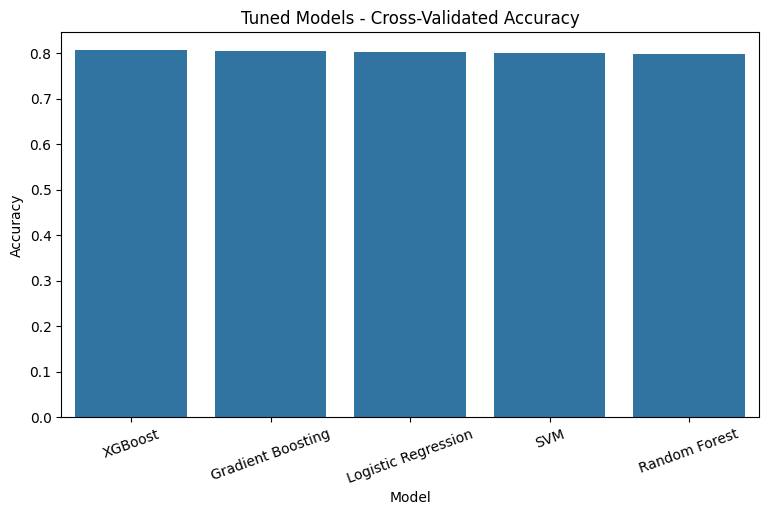

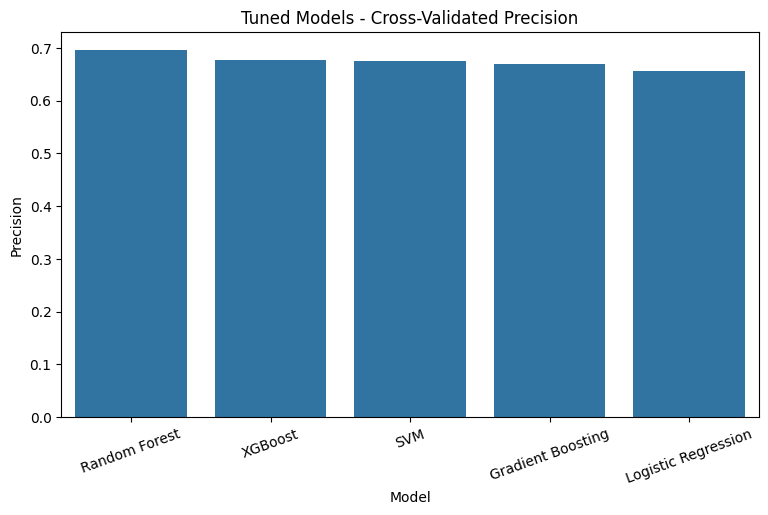

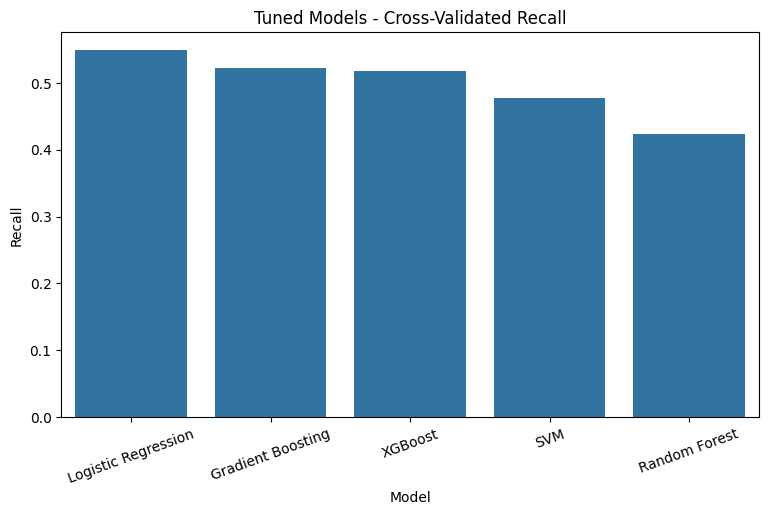

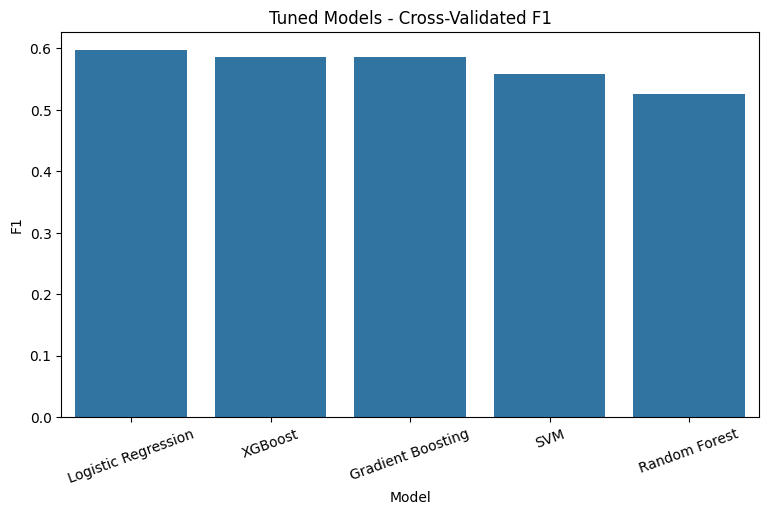

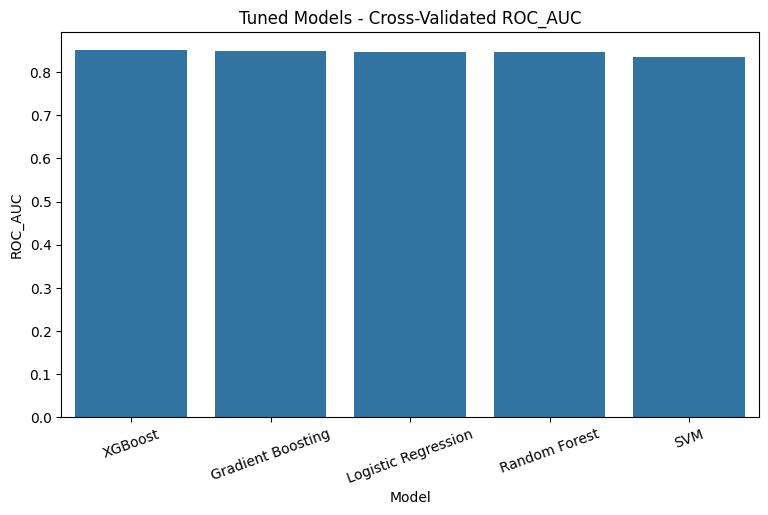

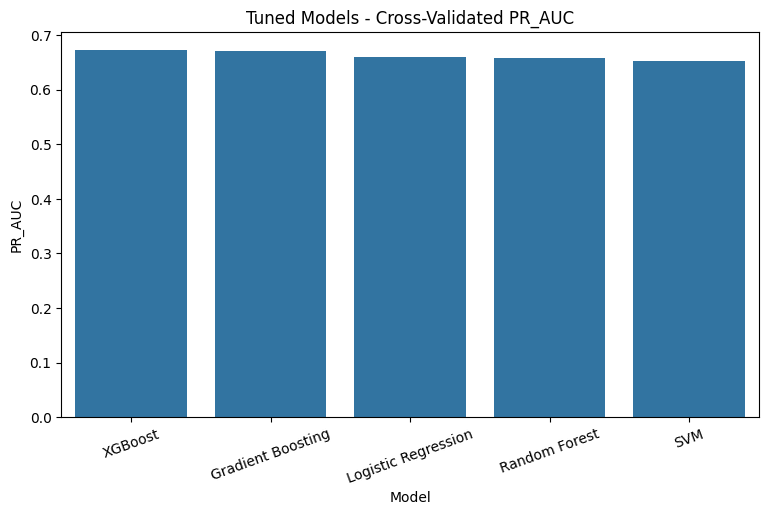

In [110]:
metrics_to_plot = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1',
    'ROC_AUC',
    'PR_AUC'
]

for metric in metrics_to_plot:
    
    plt.figure(figsize=(9, 5))
    
    sns.barplot(
        data=tuned_cv_results.sort_values(metric, ascending=False),
        x='Model',
        y=metric
    )
    
    plt.title(f'Tuned Models - Cross-Validated {metric}')
    plt.xlabel('Model')
    plt.ylabel(metric)
    plt.xticks(rotation=20)
    
    plt.show()

##  Leading Model Selection

XGBoost and Gradient Boosting achieved the strongest cross-validated ROC-AUC values and therefore will be carried forward for further evaluation.

The two models will be compared using probability-based threshold analysis. This is particularly important for customer churn because the default classification threshold of 0.50 may not provide the most appropriate balance between identifying customers at risk and limiting unnecessary retention interventions.

## Probability Threshold Analysis

Classification models commonly use a default probability threshold of 0.50 to convert predicted probabilities into class labels. However, this threshold may not be optimal for customer churn prediction.

A lower threshold may identify more customers who are likely to churn, increasing recall but potentially reducing precision. Different probability thresholds will therefore be evaluated to determine the trade-off between precision, recall, and F1-score.

The analysis will be performed using out-of-fold predictions on the training data to avoid using the test set during model selection.

In [111]:
from sklearn.model_selection import cross_val_predict

xgb_model = tuned_models['XGBoost'].best_estimator_
log_model = tuned_models['Logistic Regression'].best_estimator_

In [112]:
xgb_prob = cross_val_predict(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

log_prob = cross_val_predict(
    log_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

In [113]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

def threshold_analysis(y_true, probabilities):
    
    thresholds = np.arange(0.20, 0.71, 0.05)
    
    results = []
    
    for threshold in thresholds:
        
        predictions = (probabilities >= threshold).astype(int)
        
        results.append({
            'Threshold': threshold,
            'Precision': precision_score(y_true, predictions),
            'Recall': recall_score(y_true, predictions),
            'F1': f1_score(y_true, predictions)
        })
    
    return pd.DataFrame(results)

In [114]:
xgb_thresholds = threshold_analysis(
    y_train,
    xgb_prob
)

xgb_thresholds

,Threshold,Precision,Recall,F1
0,0.20,0.478982,0.868896,0.617542
1,0.25,0.507432,0.822074,0.627521
2,0.30,0.542803,0.771906,0.637393
3,0.35,0.575575,0.703010,0.632942
4,0.40,0.616667,0.643478,0.629787
5,0.45,0.648352,0.591973,0.618881
6,0.50,0.675983,0.517726,0.586364
7,0.55,0.699367,0.443478,0.542775
8,0.60,0.725699,0.364548,0.485307
9,0.65,0.765517,0.296990,0.427952


In [115]:
log_thresholds = threshold_analysis(
    y_train,
    log_prob
)

log_thresholds

,Threshold,Precision,Recall,F1
0,0.20,0.474639,0.857525,0.611058
1,0.25,0.508955,0.817391,0.627310
2,0.30,0.540668,0.769231,0.635008
3,0.35,0.570366,0.718395,0.635879
4,0.40,0.592926,0.661538,0.625356
5,0.45,0.624394,0.602676,0.613342
6,0.50,0.655476,0.548495,0.597232
7,0.55,0.690702,0.486957,0.571204
8,0.60,0.712067,0.398662,0.511149
9,0.65,0.754501,0.308361,0.437797


In [116]:
xgb_thresholds.loc[
    xgb_thresholds['F1'].idxmax()
]

Threshold    0.300000
Precision    0.542803
Recall       0.771906
F1           0.637393
Name: 2, dtype: float64

In [117]:
log_thresholds.loc[
    log_thresholds['F1'].idxmax()
]

Threshold    0.350000
Precision    0.570366
Recall       0.718395
F1           0.635879
Name: 3, dtype: float64

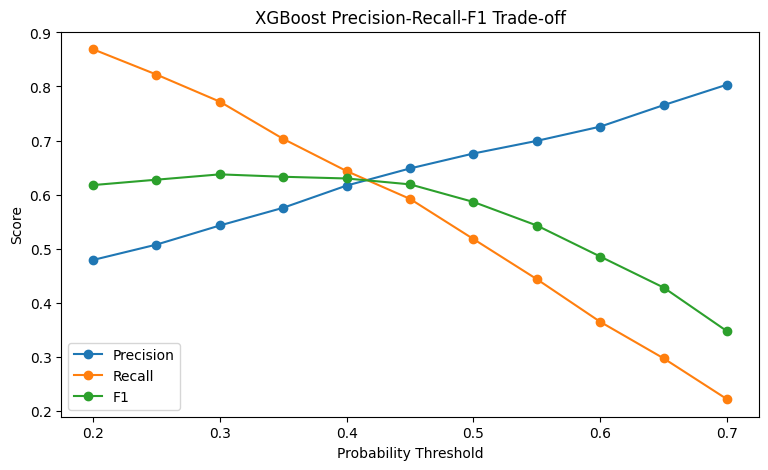

In [118]:
plt.figure(figsize=(9, 5))

plt.plot(
    xgb_thresholds['Threshold'],
    xgb_thresholds['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    xgb_thresholds['Threshold'],
    xgb_thresholds['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    xgb_thresholds['Threshold'],
    xgb_thresholds['F1'],
    marker='o',
    label='F1'
)

plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.title('XGBoost Precision-Recall-F1 Trade-off')
plt.legend()

plt.show()

##  Final Model and Classification Threshold

XGBoost achieved the highest cross-validated ROC-AUC (0.8505) and PR-AUC (0.6719) among the candidate models. Although Logistic Regression achieved a slightly higher F1-score at the default 0.50 threshold, threshold analysis demonstrated that XGBoost achieved its strongest F1-score at a probability threshold of 0.30.

At this threshold, XGBoost achieved an out-of-fold precision of approximately 54.3%, recall of approximately 77.2%, and F1-score of approximately 63.7%.

A threshold of 0.30 will therefore be carried forward for final evaluation. This threshold prioritizes identifying a larger proportion of customers at risk of churn while maintaining a reasonable balance between precision and recall.

The test set has remained completely untouched during model selection and threshold selection.

In [119]:
final_model = tuned_models['XGBoost'].best_estimator_

final_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [120]:
test_probabilities = final_model.predict_proba(X_test)[:, 1]

In [121]:
final_threshold = 0.30

y_test_pred = (
    test_probabilities >= final_threshold
).astype(int)

##  Final Model Evaluation on the Unseen Test Set

The final tuned XGBoost model is evaluated on the previously unseen test set. The test set was not used during preprocessing fitting, cross-validation, hyperparameter tuning, model selection, or threshold selection.

This provides an unbiased estimate of how the final model is expected to perform on new customers.

In [123]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

In [124]:
final_metrics = {
    'Accuracy': accuracy_score(y_test, y_test_pred),
    'Precision': precision_score(y_test, y_test_pred),
    'Recall': recall_score(y_test, y_test_pred),
    'F1': f1_score(y_test, y_test_pred),
    'ROC_AUC': roc_auc_score(y_test, test_probabilities),
    'PR_AUC': average_precision_score(y_test, test_probabilities)
}

final_results = pd.DataFrame(
    [final_metrics],
    index=['Final XGBoost']
)

final_results

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Final XGBoost,0.757984,0.530055,0.778075,0.630553,0.847676,0.662878


In [125]:
print(classification_report(
    y_test,
    y_test_pred,
    target_names=['No Churn', 'Churn']
))

              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



In [126]:
cm = confusion_matrix(y_test, y_test_pred)

cm

array([[777, 258],
       [ 83, 291]])

##  Confusion Matrix

The confusion matrix provides a detailed breakdown of correct and incorrect predictions for churn and non-churn customers.

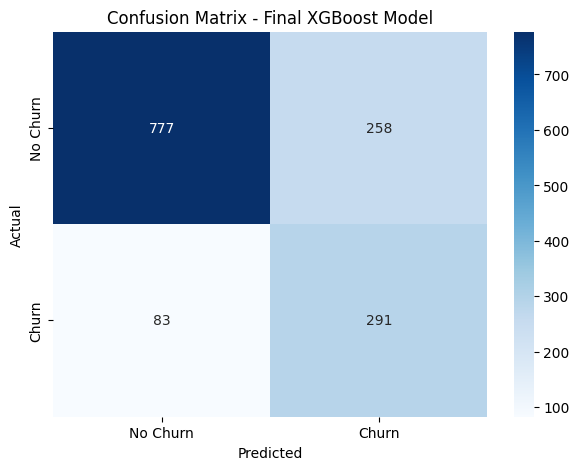

In [127]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title('Confusion Matrix - Final XGBoost Model')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

##  ROC Curve

The ROC curve evaluates the model's ability to distinguish between customers who churn and customers who do not churn across different classification thresholds.

The area under the ROC curve (ROC-AUC) summarizes this discrimination ability.

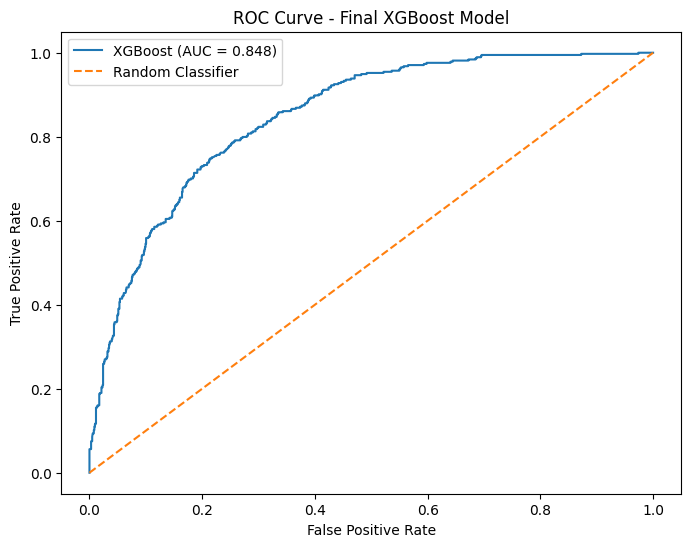

In [128]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'XGBoost (AUC = {final_metrics["ROC_AUC"]:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Final XGBoost Model')
plt.legend()

plt.show()

## Precision-Recall Curve

Because churners represent a minority of the customer base, the Precision-Recall curve provides an important complementary evaluation to the ROC curve.

It shows the trade-off between precision and recall across different probability thresholds.

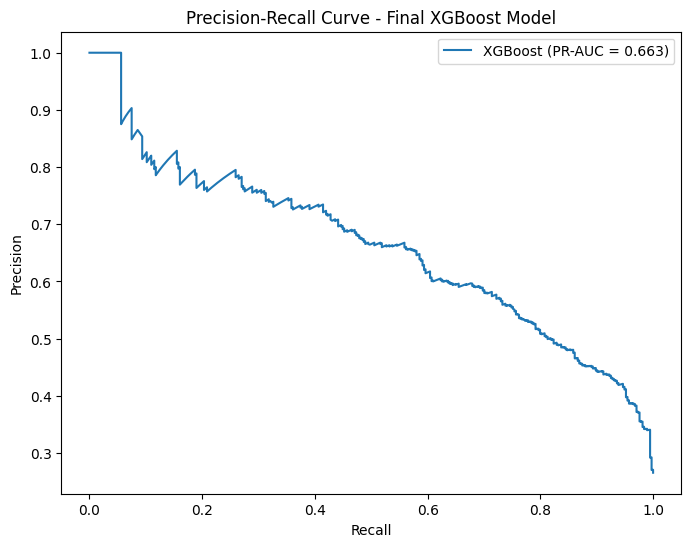

In [129]:
from sklearn.metrics import precision_recall_curve

precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f'XGBoost (PR-AUC = {final_metrics["PR_AUC"]:.3f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Final XGBoost Model')
plt.legend()

plt.show()

## Feature Importance

Feature importance is used to identify the variables that contribute most to the XGBoost model's predictions.

In [130]:
feature_names = final_model.named_steps['preprocessor'].get_feature_names_out()

importances = final_model.named_steps['model'].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

feature_importance.head(15)

,Feature,Importance
36,cat__Contract_Month-to-month,0.364595
16,cat__InternetService_Fiber optic,0.081325
27,cat__TechSupport_No,0.072551
18,cat__OnlineSecurity_No,0.064860
15,cat__InternetService_DSL,0.044493
43,cat__PaymentMethod_Electronic check,0.039653
40,cat__PaperlessBilling_Yes,0.031957
1,num__tenure,0.030524
38,cat__Contract_Two year,0.029602
35,cat__StreamingMovies_Yes,0.016443


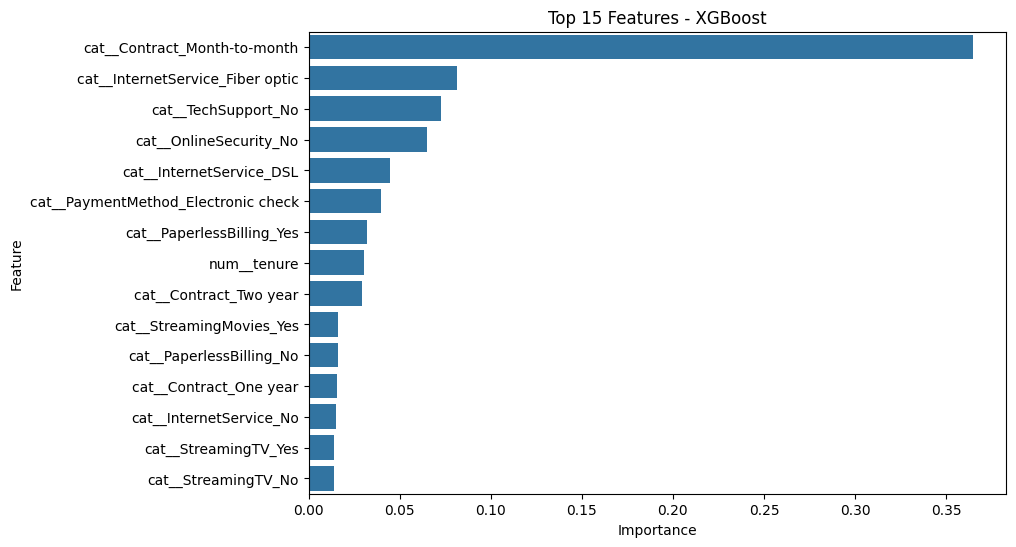

In [132]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Features - XGBoost')
plt.show()

##  Save Final Model

The final trained model and selected classification threshold are saved so that the model can be reused for future predictions without retraining.

In [133]:
import joblib

model_package = {
    'model': final_model,
    'threshold': 0.30
}

joblib.dump(
    model_package,
    'customer_churn_xgboost_final.pkl'
)

['customer_churn_xgboost_final.pkl']

In [134]:
import os

os.path.getsize('customer_churn_xgboost_final.pkl')

132240

##  Final Results

The final XGBoost model achieved a test ROC-AUC of 0.848 and PR-AUC of 0.663. Using a probability threshold of 0.30, the model achieved 77.8% recall and 63.1% F1-score.

The lower classification threshold substantially increased the model's ability to identify customers who churn compared with the default 0.50 threshold.

The model therefore provides a useful predictive tool for identifying customers who may be at increased risk of churn and could benefit from targeted retention strategies.

In [135]:
final_results

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Final XGBoost,0.757984,0.530055,0.778075,0.630553,0.847676,0.662878


##  Conclusion

This project developed an end-to-end machine-learning system for predicting customer churn.

The workflow included data cleaning, exploratory data analysis, feature preprocessing, cross-validation, comparison of multiple classification algorithms, hyperparameter tuning, probability-threshold optimization, and final evaluation on an unseen test set.

XGBoost was selected as the final model because it achieved the highest cross-validated ROC-AUC and PR-AUC among the candidate models. A probability threshold of 0.30 was selected to improve the identification of customers at risk of churn.

On the unseen test set, the final model achieved a ROC-AUC of 0.8477, PR-AUC of 0.6629, recall of 77.8%, precision of 53.0%, and F1-score of 63.1%.

The results demonstrate that machine learning can provide useful predictive information for customer retention. However, the model should be validated on future customer data before being deployed in a production environment. In practice, the optimal probability threshold should also be determined according to the financial cost of retention campaigns and the value of successfully retaining a customer.